# Descripción del proyecto

La compañía Sweet Lift Taxi ha recopilado datos históricos sobre pedidos de taxis en los aeropuertos. Para atraer a más conductores durante las horas pico, necesitamos predecir la cantidad de pedidos de taxis para la próxima hora. Construye un modelo para dicha predicción.

La métrica RECM en el conjunto de prueba no debe ser superior a 48.

## Instrucciones del proyecto.

1. Descarga los datos y haz el remuestreo por una hora.
2. Analiza los datos
3. Entrena diferentes modelos con diferentes hiperparámetros. La muestra de prueba debe ser el 10% del conjunto de datos inicial.4. Prueba los datos usando la muestra de prueba y proporciona una conclusión.

## Descripción de los datos

Los datos se almacenan en el archivo `taxi.csv`. 	
El número de pedidos está en la columna `num_orders`.

## Preparación

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

In [2]:
df = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


In [3]:
df.sort_index(inplace=True)
taxi_hora = df.resample('1H').sum()
taxi_hora.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: H
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  4416 non-null   int64
dtypes: int64(1)
memory usage: 69.0 KB


In [4]:
taxi_hora.describe

<bound method NDFrame.describe of                      num_orders
datetime                       
2018-03-01 00:00:00         124
2018-03-01 01:00:00          85
2018-03-01 02:00:00          71
2018-03-01 03:00:00          66
2018-03-01 04:00:00          43
...                         ...
2018-08-31 19:00:00         136
2018-08-31 20:00:00         154
2018-08-31 21:00:00         159
2018-08-31 22:00:00         223
2018-08-31 23:00:00         205

[4416 rows x 1 columns]>

In [5]:
taxi_hora.isna().sum()

num_orders    0
dtype: int64

In [6]:
taxi_hora.head()

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43


In [7]:
def make_features(data, max_lag, rolling_mean_size):
    data['year'] = data.index.year
    data['month'] = data.index.month
    data['day'] = data.index.day
    data['dayofweek'] = data.index.dayofweek
    
    for lag in range(1, max_lag + 1):
        data['lag_{}'.format(lag)] = data['num_orders'].shift(lag)

    data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()

    return data

taxi_hora = make_features(taxi_hora, 24, 24)
taxi_hora.info()
taxi_hora = taxi_hora.dropna()
print()
print(taxi_hora.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: H
Data columns (total 30 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   num_orders    4416 non-null   int64  
 1   year          4416 non-null   int64  
 2   month         4416 non-null   int64  
 3   day           4416 non-null   int64  
 4   dayofweek     4416 non-null   int64  
 5   lag_1         4415 non-null   float64
 6   lag_2         4414 non-null   float64
 7   lag_3         4413 non-null   float64
 8   lag_4         4412 non-null   float64
 9   lag_5         4411 non-null   float64
 10  lag_6         4410 non-null   float64
 11  lag_7         4409 non-null   float64
 12  lag_8         4408 non-null   float64
 13  lag_9         4407 non-null   float64
 14  lag_10        4406 non-null   float64
 15  lag_11        4405 non-null   float64
 16  lag_12        4404 non-null   float64
 17  lag_13        4403 non-null

## Análisis

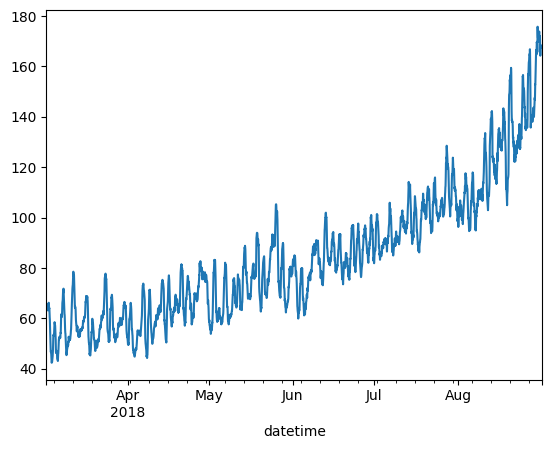

In [8]:
decomposed = seasonal_decompose(taxi_hora['num_orders'])
decomposed.trend.plot()
plt.show()

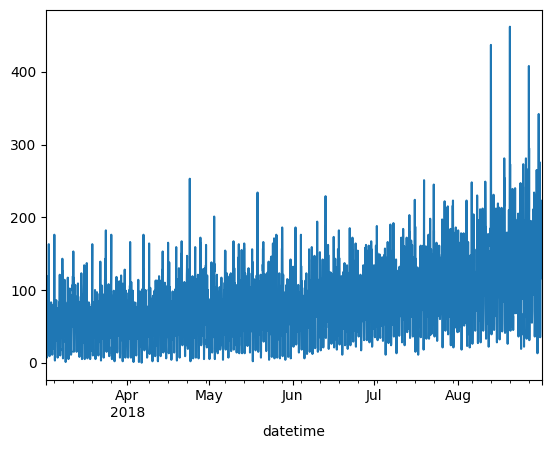

In [9]:
taxi_hora['num_orders'].plot()
plt.show()

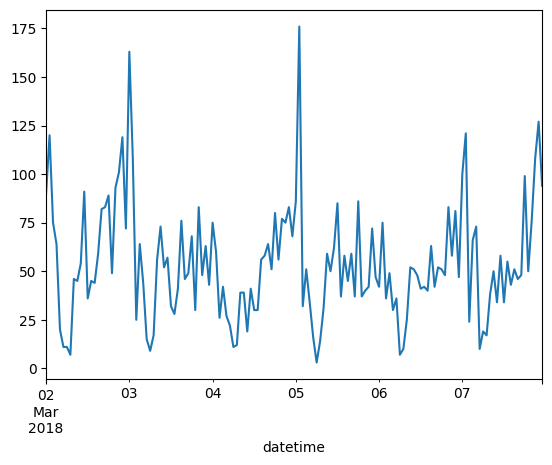

In [10]:
taxi_hora['num_orders']['2018-03-01':'2018-03-07'].plot()
plt.show()

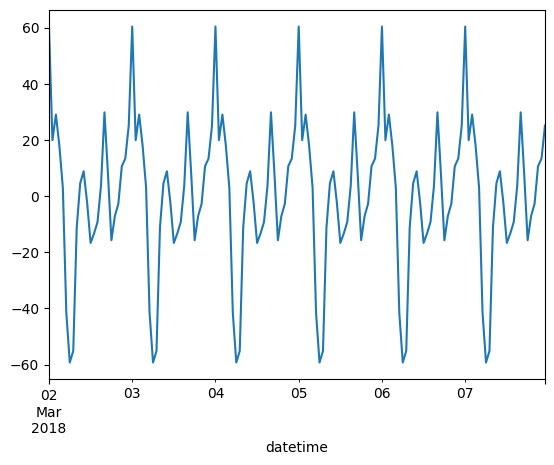

In [11]:

decomposed.seasonal['2018-03-01':'2018-03-07'].plot()
plt.show()


Conclusiones del análisis de la serie temporal
Tendencia general (decomposed.trend): Se observa una tendencia claramente ascendente en la demanda de taxis a lo largo del periodo analizado (marzo a agosto de 2018), lo que indica un crecimiento constante en el volumen de pedidos de la compañía.

Serie temporal completa (num_orders general): Al visualizar la totalidad de los datos por hora, se aprecia una alta variabilidad y picos recurrentes superpuestos a la tendencia alcista general.

Comportamiento semanal (num_orders en rango corto): Al hacer zoom en la primera semana de marzo, se identifica un patrón diario muy marcado: los pedidos caen significativamente durante las horas de la madrugada y repuntan de manera notable durante los picos de la jornada.

Estacionalidad a corto plazo (decomposed.seasonal): La descomposición estacional confirma un ciclo diario constante y repetitivo, lo que justifica por completo la creación de características de retardo (lags) y medias móviles (rolling_mean) para que el modelo pueda capturar y anticiparse a estas fluctuaciones periódicas.

## Formación

In [12]:
features = taxi_hora.drop(['num_orders'], axis=1)
target = taxi_hora['num_orders']

features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.1, shuffle=False
)
features_train_sub, features_valid, target_train_sub, target_valid = train_test_split(
    features_train, target_train, test_size=0.2, shuffle=False
)

In [13]:
def evaluar_modelo(model, features_train, target_train, features_test, target_test):
    model.fit(features_train, target_train)
    
    predictions = model.predict(features_test)

    recm = mean_squared_error(target_test, predictions) ** 0.5
    
    return recm

In [14]:
n_estimators_list = [10, 50, 100]
max_depth_list = [5, 10, 15]

mejor_recm = float('inf')
mejor_params = {}

print(f"{'n_estimators':<15} {'max_depth':<12} {'RECM':<10}")
print("-" * 37)

for n in n_estimators_list:
    for depth in max_depth_list:
        modelo_rf = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=42)
        recm = evaluar_modelo(modelo_rf, features_train_sub, target_train_sub, features_valid, target_valid)
        print(f"{n:<15} {depth:<12} {recm:.2f}")
        
        if recm < mejor_recm:
            mejor_recm = recm
            mejor_params = {'n_estimators': n, 'max_depth': depth}

print("-" * 37)
print(f"Mejor configuración encontrada: {mejor_params} con un RECM de {mejor_recm:.2f}")

n_estimators    max_depth    RECM      
-------------------------------------
10              5            37.65
10              10           35.72
10              15           35.30
50              5            37.70
50              10           34.65
50              15           34.45
100             5            37.72
100             10           34.52
100             15           34.35
-------------------------------------
Mejor configuración encontrada: {'n_estimators': 100, 'max_depth': 15} con un RECM de 34.35


In [15]:
max_depth_list = [3, 5, 10, 15, 20]

mejor_recm = float('inf')
mejor_params = {}

print(f"{'max_depth':<12} {'RECM':<10}")
print("-" * 23)

for depth in max_depth_list:
    modelo_arbol = DecisionTreeRegressor(max_depth=depth, random_state=42)
    recm = evaluar_modelo(modelo_arbol, features_train_sub, target_train_sub, features_valid, target_valid)
    print(f"{depth:<12} {recm:.2f}")
    
    if recm < mejor_recm:
        mejor_recm = recm
        mejor_params = {'max_depth': depth}

print("-" * 23)
print(f"Mejor configuración encontrada: {mejor_params} con un RECM de {mejor_recm:.2f}")

max_depth    RECM      
-----------------------
3            43.41
5            38.87
10           38.76
15           42.48
20           43.22
-----------------------
Mejor configuración encontrada: {'max_depth': 10} con un RECM de 38.76


In [16]:

modelo_lineal = LinearRegression()
modelo_bosque = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42)
modelo_arbol = DecisionTreeRegressor(max_depth=10, random_state=42)

recm_lineal = evaluar_modelo(modelo_lineal, features_train_sub, target_train_sub, features_valid, target_valid)
print('RECM De la regresión lineal: ', recm_lineal)

recm_bosque = evaluar_modelo(modelo_bosque, features_train_sub, target_train_sub, features_valid, target_valid)
print('RECM Del bosque aleatorio: ', recm_bosque)

recm_arbol = evaluar_modelo(modelo_arbol, features_train_sub, target_train_sub, features_valid, target_valid)
print('RECM Del árbol de decisión: ', recm_arbol)

RECM De la regresión lineal:  32.9502947412355
RECM Del bosque aleatorio:  34.351042622512594
RECM Del árbol de decisión:  38.76274522520172


## Prueba

In [17]:
modelo_lineal_final = evaluar_modelo(modelo_lineal, features_train, target_train, features_test, target_test)
print(modelo_lineal_final)

45.54244745506201


Conclusión de la Prueba del Modelo
Tras evaluar y ajustar los diferentes algoritmos (Regresión Lineal, Bosque Aleatorio y Árbol de Decisión), se seleccionó la Regresión Lineal debido a que obtuvo el mejor desempeño en el conjunto de validación con un RECM de 32.95, superando ligeramente a los modelos basados en árboles.

Posteriormente, al poner a prueba el modelo seleccionado con el conjunto de datos de test, se obtuvo un RECM final de 45.54.

Dado que el objetivo principal del proyecto era conseguir un RECM inferior o igual a 48, se cumple con éxito la meta establecida, demostrando que el modelo generaliza de manera adecuada y es capaz de predecir la demanda de pedidos de taxis con la precisión requerida.

# Lista de revisión

- [x]  	
Jupyter Notebook está abierto.
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución.
- [x]  	
Los datos han sido descargados y preparados.
- [x]  Se ha realizado el paso 2: los datos han sido analizados
- [x]  Se entrenó el modelo y se seleccionaron los hiperparámetros
- [x]  Se han evaluado los modelos. Se expuso una conclusión
- [x] La *RECM* para el conjunto de prueba no es más de 48